# Chromosome 6 Coverage and MHC Gene Analysis

**Diana Naseh · Bioinformatics course project**

This notebook documents an exploratory analysis of 16 chromosome-6 BAM files from an 80-sample course dataset. It combines GENCODE v19 annotations with alignment-quality summaries and gene-span coverage measurements, with a focused view of selected MHC-related genes.

**Status: archived analysis with original saved outputs.** The input BAM files are no longer available to the author. This edition improves the explanations, comments, and formatting without rerunning the analysis or changing the retained executable calculations. The saved outputs have not been independently reproduced. Original execution counts are retained, including their nonsequential order.

The notebook is intended to be read without execution. Installation commands, file paths, and checks document the original Colab workflow; running them requires the original inputs and environment. No rerun is needed to view the embedded figures.

## Scope

- Inspect chromosome 6 annotations and example alignment records.
- Summarize read length, pairing, and mapping quality.
- Compare gene-span coverage across the assigned samples.
- Examine depth and zero-depth fractions in selected MHC genes.

The original reference-sequence matching section has been removed from this presentation because it did not infer sample-specific HLA alleles. This notebook makes no genotype or allele-frequency claims. Known limitations of the retained coverage calculations are documented beside the relevant results.

## Original software setup

The following commands and imports are retained as a record of the original environment setup. They are not a pinned or independently tested environment specification. The verbose installation output has been omitted.

In [1]:
! apt-get update -y
! apt-get install -y samtools bedtools
!pip install --quiet pysam gffutils biopython pandas matplotlib numpy


In [2]:
import os
import re
import math
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pysam

from Bio import SeqIO
from Bio.Align import PairwiseAligner


## 1. Inputs and sample selection

The analysis uses 16 assigned samples, GENCODE v19 gene annotations, and a chromosome 6 reference FASTA. The paths below refer to the original Google Drive layout. Drive was mounted outside the saved cells; that prerequisite is not included in this notebook.

The original setup also checks for an IMGT/HLA FASTA. That check remains for provenance, although the allele-matching section is not included in this edition. File presence alone does not establish assembly compatibility or database release provenance.

In [3]:
DRIVE_BASE = "/content/drive/MyDrive/Bioinformatics/Assignments/Assignment1"
BAM_DIR = os.path.join(DRIVE_BASE, "data")
OUTPUT_DIR = os.path.join(DRIVE_BASE, "output")
REF_DIR = os.path.join(DRIVE_BASE, "reference")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(REF_DIR, exist_ok=True)

SAMPLES = [
    "MOT36440","MOT36441","MOT36442","MOT36443","MOT36446","MOT36447",
    "MOT36449","MOT36450","MOT36451","MOT36452","MOT36453","MOT36455",
    "MOT36456","MOT36457","MOT36458","MOT36459"
]
BAM_PATHS = {s: os.path.join(BAM_DIR, f"{s}.bam") for s in SAMPLES}

GTF_PATH  = os.path.join(REF_DIR, "gencode.v19.annotation.gtf")
CHR6_FA   = os.path.join(REF_DIR, "chr6.fa")
HLA_FASTA = os.path.join(REF_DIR, "hla_gen.fasta")

files = {
    "GENCODE v19 GTF": GTF_PATH,
    "hg19 chr6 FASTA": CHR6_FA,
    "HLA allele FASTA": HLA_FASTA,
}
for name, path in files.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")


GENCODE v19 GTF: FOUND
hg19 chr6 FASTA: FOUND
HLA allele FASTA: FOUND


## 2. Chromosome 6 gene annotations

The GTF is inspected before extracting records with feature type `gene` on chromosome 6. Coordinates remain in the GTF's 1-based inclusive convention; downstream pysam interval queries subtract one from the start coordinate.

**Identifier limitation:** the original code uses gene symbols as matrix keys. Symbols are not necessarily unique. In particular, the saved MHC output contains two `CFB` annotation records. Distinct records can therefore be overwritten or conflated. Resolving them by gene ID requires a revised analysis and cannot be corrected while retaining these results.

In [4]:
GTF_FILE  = GTF_PATH
genes_out = os.path.join(OUTPUT_DIR, "genes_chr6_master_table.csv")

if not os.path.exists(GTF_FILE):
    raise FileNotFoundError(f"GTF file not found: {GTF_FILE}")

print("GTF file size (MB):", round(os.path.getsize(GTF_FILE) / (1024**2), 2))

# Inspect a small GTF preview.
header_lines = []
data_preview = []

with open(GTF_FILE, "rt") as fh:
    for line in fh:
        if line.startswith("#"):
            if len(header_lines) < 5:
                header_lines.append(line.rstrip("\n"))
            continue
        if len(data_preview) < 3:
            data_preview.append(line.rstrip("\n"))
        if len(data_preview) >= 3:
            break

print("\nFirst header lines:")
if header_lines:
    for h in header_lines:
        print(h)
else:
    print("(no header lines)")

print("\nFirst 3 data lines (raw GTF):")
for line in data_preview:
    print(line)

def parse_gtf_attributes(attr_str: str) -> dict:
    out = {}
    for item in attr_str.strip().split(";"):
        item = item.strip()
        if not item:
            continue
        m = re.match(r'(\S+)\s+"([^"]+)"', item)
        if m:
            out[m.group(1)] = m.group(2)
    return out

# Summarize feature types and inspect one gene record.
feature_counts = {}
seqname_counts = {}
example_gene_row = None

with open(GTF_FILE, "rt") as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        parts = line.rstrip("\n").split("\t")
        if len(parts) != 9:
            continue
        seqname, source, feature, start, end, score, strand, frame, attributes = parts
        feature_counts[feature] = feature_counts.get(feature, 0) + 1
        seqname_counts[seqname] = seqname_counts.get(seqname, 0) + 1

        if example_gene_row is None and feature == "gene":
            attrs = parse_gtf_attributes(attributes)
            example_gene_row = {
                "seqname": seqname,
                "feature": feature,
                "start": int(start),
                "end": int(end),
                "strand": strand,
                "gene_id": attrs.get("gene_id"),
                "gene_name": attrs.get("gene_name"),
                "gene_type": attrs.get("gene_type") or attrs.get("gene_biotype"),
            }

print("\n--- Quick overview ---")
top_features = sorted(feature_counts.items(), key=lambda x: x[1], reverse=True)[:10]
print("Top feature types (first 10):")
for f, n in top_features:
    print(f"  {f:12s}: {n}")

top_seqnames = sorted(seqname_counts.items(), key=lambda x: x[1], reverse=True)[:10]
print("\nMost common seqname values (first 10):")
for s, n in top_seqnames:
    print(f"  {s:6s}: {n}")

if example_gene_row:
    print("\nExample interpreted 'gene' row:")
    for k, v in example_gene_row.items():
        print(f"  {k:10s}: {v}")

# Extract chromosome 6 gene records.
chr6_aliases = {"6", "chr6", "Chr6", "CHR6", "chr06"}

rows = []
with open(GTF_FILE, "rt") as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        parts = line.rstrip("\n").split("\t")
        if len(parts) != 9:
            continue

        seqname, source, feature, start, end, score, strand, frame, attributes = parts
        if feature != "gene":
            continue
        if seqname not in chr6_aliases:
            continue

        attrs = parse_gtf_attributes(attributes)
        gene_name = attrs.get("gene_name") or attrs.get("gene_id")

        rows.append({
            "gene_name": gene_name,
            "seqname": seqname,
            "start": int(start),
            "end": int(end),
            "strand": strand,
            "attributes": attributes
        })

genes_df = pd.DataFrame(rows).sort_values("start").reset_index(drop=True)

print("\nchr6 gene table rows:", len(genes_df))
genes_df.to_csv(genes_out, index=False)
print("Saved chr6 gene master table ->", genes_out)


GTF file size (MB): 1121.11

First header lines:
##description: evidence-based annotation of the human genome (GRCh37), version 19 (Ensembl 74)
##provider: GENCODE
##contact: gencode@sanger.ac.uk
##format: gtf
##date: 2013-12-05

First 3 data lines (raw GTF):
chr1	HAVANA	gene	11869	14412	.	+	.	gene_id "ENSG00000223972.4"; transcript_id "ENSG00000223972.4"; gene_type "pseudogene"; gene_status "KNOWN"; gene_name "DDX11L1"; transcript_type "pseudogene"; transcript_status "KNOWN"; transcript_name "DDX11L1"; level 2; havana_gene "OTTHUMG00000000961.2";
chr1	HAVANA	transcript	11869	14409	.	+	.	gene_id "ENSG00000223972.4"; transcript_id "ENST00000456328.2"; gene_type "pseudogene"; gene_status "KNOWN"; gene_name "DDX11L1"; transcript_type "processed_transcript"; transcript_status "KNOWN"; transcript_name "DDX11L1-002"; level 2; tag "basic"; havana_gene "OTTHUMG00000000961.2"; havana_transcript "OTTHUMT00000362751.1";
chr1	HAVANA	exon	11869	12227	.	+	.	gene_id "ENSG00000223972.4"; transcript_id

## 3. Example BAM records

The first available BAM is inspected to show reference names, positions, mapping qualities, and CIGAR strings. This is a small file-order preview, not a representative sample of the dataset.

The example header lists 93 references. A reference dictionary can contain contigs with no alignments in a supplied subset; the preview alone does not verify the genomic extent of every BAM.

In [5]:
example_sample = None
example_bam = None
for s in SAMPLES:
    p = BAM_PATHS[s]
    if os.path.exists(p):
        example_sample = s
        example_bam = p
        break

if example_bam is None:
    raise FileNotFoundError("No BAM files found in BAM_DIR. Check your paths.")

print("Example sample:", example_sample)
print("BAM path:", example_bam)

bam = pysam.AlignmentFile(example_bam, "rb")
print("Number of references in BAM header:", bam.nreferences)

print("\nFirst 5 reads in the BAM:")
shown = 0
for read in bam.fetch(until_eof=True):
    ref = read.reference_name if read.reference_id != -1 else "*"
    pos1 = (read.reference_start + 1) if read.reference_id != -1 else None
    print(f"Read {shown+1}:")
    print("  query_name:", read.query_name)
    print("  mapped?:", (not read.is_unmapped), "| ref:", ref, "| pos(1-based):", pos1)
    print("  MAPQ:", read.mapping_quality, "| CIGAR:", read.cigarstring)
    shown += 1
    if shown >= 5:
        break

bam.close()


Example sample: MOT36440
BAM path: /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/data/MOT36440.bam
Number of references in BAM header: 93

First 5 reads in the BAM:
Read 1:
  query_name: MOT36440:183:233G7FLT4:2:1488:21710:14284
  mapped?: True | ref: chr6 | pos(1-based): 10000278
  MAPQ: 60 | CIGAR: 151M
Read 2:
  query_name: MOT36440:183:233G7FLT4:2:1488:21710:14284
  mapped?: True | ref: chr6 | pos(1-based): 10000538
  MAPQ: 60 | CIGAR: 151M
Read 3:
  query_name: MOT36440:183:233G7FLT4:2:1445:12043:22817
  mapped?: True | ref: chr6 | pos(1-based): 10000696
  MAPQ: 60 | CIGAR: 151M
Read 4:
  query_name: MOT36440:183:233G7FLT4:2:2427:42235:27581
  mapped?: True | ref: chr6 | pos(1-based): 10000731
  MAPQ: 60 | CIGAR: 151M
Read 5:
  query_name: MOT36440:183:233G7FLT4:2:1445:12043:22817
  mapped?: True | ref: chr6 | pos(1-based): 10000789
  MAPQ: 60 | CIGAR: 151M


### Read-length and pairing overview

The next cell examines the first 200,000 primary records with available read lengths in each BAM. Secondary and supplementary alignments are excluded. This is a file-order sample, not random sampling; in a coordinate-sorted BAM it favors the earlier genomic portion.

Pairing fractions below describe the inspected records. They are not estimates of complete-library quality.

In [6]:
N_READS_TO_SAMPLE = 200_000

def approximate_read_lengths_and_pairing(bam_path: str, n_reads: int):
    bam = pysam.AlignmentFile(bam_path, "rb")

    lengths = []
    aligned_lengths = []
    paired_flags = []
    proper_flags = []

    seen = 0
    for read in bam.fetch(until_eof=True):
        if read.is_secondary or read.is_supplementary:
            continue
        if read.query_length is None:
            continue

        lengths.append(int(read.query_length))
        aligned_lengths.append(int(read.query_alignment_length))
        paired_flags.append(bool(read.is_paired))
        proper_flags.append(bool(read.is_proper_pair))

        seen += 1
        if seen >= n_reads:
            break

    bam.close()

    if not lengths:
        return {
            "reads_sampled": 0,
            "min_read_length": np.nan,
            "max_read_length": np.nan,
            "mean_read_length": np.nan,
            "median_read_length": np.nan,
            "mean_aligned_length": np.nan,
            "paired_fraction": np.nan,
            "proper_pair_fraction": np.nan,
        }

    lengths = np.array(lengths, dtype=int)
    aligned_lengths = np.array(aligned_lengths, dtype=int)
    paired_flags = np.array(paired_flags, dtype=bool)
    proper_flags = np.array(proper_flags, dtype=bool)

    return {
        "reads_sampled": int(len(lengths)),
        "min_read_length": int(lengths.min()),
        "max_read_length": int(lengths.max()),
        "mean_read_length": float(lengths.mean()),
        "median_read_length": float(np.median(lengths)),
        "mean_aligned_length": float(aligned_lengths.mean()),
        "paired_fraction": float(paired_flags.mean()),
        "proper_pair_fraction": float(proper_flags.mean()),
    }

rows = []
for sample, bam_path in BAM_PATHS.items():
    if not os.path.exists(bam_path):
        print(f"Skipping {sample}: BAM not found.")
        continue
    stats = approximate_read_lengths_and_pairing(bam_path, N_READS_TO_SAMPLE)
    rows.append({"sample": sample, **stats})

readlen_df = pd.DataFrame(rows).sort_values("sample")
display(readlen_df)

out_csv = os.path.join(OUTPUT_DIR, "task1_read_length_and_pairing_summary.csv")
readlen_df.to_csv(out_csv, index=False)
print("Saved read length summary ->", out_csv)


,sample,reads_sampled,min_read_length,max_read_length,mean_read_length,median_read_length,mean_aligned_length,paired_fraction,proper_pair_fraction
0,MOT36440,200000,151,151,151.0,151.0,149.044085,1.0,0.992685
1,MOT36441,200000,151,151,151.0,151.0,149.405970,1.0,0.991795
2,MOT36442,200000,151,151,151.0,151.0,149.016215,1.0,0.992360
3,MOT36443,200000,151,151,151.0,151.0,149.087720,1.0,0.991405
4,MOT36446,200000,151,151,151.0,151.0,149.062110,1.0,0.991355
5,MOT36447,200000,151,151,151.0,151.0,149.216980,1.0,0.994360
6,MOT36449,200000,151,151,151.0,151.0,149.591750,1.0,0.993425
7,MOT36450,200000,151,151,151.0,151.0,142.074160,1.0,0.994430
8,MOT36451,200000,151,151,151.0,151.0,149.171125,1.0,0.992210
9,MOT36452,200000,151,151,151.0,151.0,149.295850,1.0,0.991720


Saved read length summary -> /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/task1_read_length_and_pairing_summary.csv


**Saved observation.** The inspected records have a reported read length of 151 bases in every sample. Mean aligned lengths differ across samples; the file-order sampling design limits how broadly those differences can be interpreted.

## 4. Gene annotation and original coverage estimates

For each gene interval, the code checks for an overlapping mapped alignment with MAPQ at least 30, excluding secondary and supplementary alignments. It then exports an annotation table and a reference sequence and computes the original pileup-based metrics.

**Sequence provenance:** `sequence` is extracted from `chr6.fa`, not reconstructed from sample reads. The same genomic interval therefore yields the same reference sequence across samples. Extraction uses reference-forward orientation; negative-strand genes are not reverse-complemented in this implementation.

**Coverage limitations:** the read-presence test and pileup use different filtering behavior. `col.nsegments` counts pileup segments rather than explicitly counted high-quality A/C/G/T bases, and the implementation does not set all pileup options. The reported covered fraction counts emitted pileup positions. These are the original operational measurements, not a newly validated depth definition.

Gene spans include introns. Missing BAMs are skipped in the original code, and missing matrix entries are later filled with zero. Thus a zero in the plotted matrix does not by itself prove a successfully measured absence of coverage. All 16 samples appear in the saved QC summaries, but no fresh input validation is possible.

In [7]:
MIN_MAPQ = 30
FILTER_SECONDARY = True
FILTER_SUPP = True

GENES_CSV = genes_out

genes_df = pd.read_csv(GENES_CSV)

# Read the contig name used by the original reference FASTA.
if not os.path.exists(CHR6_FA + ".fai"):
    raise FileNotFoundError("Missing FASTA index chr6.fa.fai. Run: samtools faidx chr6.fa")

with open(CHR6_FA + ".fai", "r") as f:
    fasta_headers = [line.split()[0] for line in f]

if "chr6" in fasta_headers:
    refname = "chr6"
elif "6" in fasta_headers:
    refname = "6"
else:
    refname = fasta_headers[0]

print("FASTA contig name used for chr6:", refname)
print("Total genes in chr6 master table:", len(genes_df))

def fetch_seq_samtools(fasta_path: str, chrom: str, start_1based: int, end_1based: int) -> str:
    region = f"{chrom}:{start_1based}-{end_1based}"
    res = subprocess.run(["samtools", "faidx", fasta_path, region], capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(f"samtools faidx failed for {region}: {res.stderr}")
    lines = res.stdout.splitlines()
    return "".join(lines[1:]) if len(lines) > 1 else ""

def read_passes_filters(read) -> bool:
    if read.is_unmapped:
        return False
    if FILTER_SECONDARY and read.is_secondary:
        return False
    if FILTER_SUPP and read.is_supplementary:
        return False
    if read.mapping_quality < MIN_MAPQ:
        return False
    return True

def gene_has_any_read(bam: pysam.AlignmentFile, chrom: str, start_1based: int, end_1based: int) -> bool:
    for read in bam.fetch(chrom, start_1based - 1, end_1based):
        if read_passes_filters(read):
            return True
    return False

def gene_coverage_metrics(bam: pysam.AlignmentFile, chrom: str, start_1based: int, end_1based: int):
    region_len = end_1based - start_1based + 1
    if region_len <= 0:
        return 0.0, 0.0

    depth_sum = 0
    covered_bases = 0

    for col in bam.pileup(
        chrom,
        start_1based - 1,
        end_1based,
        truncate=True,
        stepper="samtools",
        min_mapping_quality=MIN_MAPQ
    ):
        depth_sum += col.nsegments
        covered_bases += 1

    mean_depth = depth_sum / region_len
    covered_fraction = covered_bases / region_len
    return float(mean_depth), float(covered_fraction)

coverage_dir = os.path.join(OUTPUT_DIR, "task1_gene_coverage")
top10_dir    = os.path.join(OUTPUT_DIR, "task1_top10_lists")
os.makedirs(coverage_dir, exist_ok=True)
os.makedirs(top10_dir, exist_ok=True)

coverage_matrix = {}  # Original matrix keys are gene symbols, which may repeat.

for i, (sample, bam_path) in enumerate(BAM_PATHS.items(), start=1):
    print(f"\n[{i}/{len(BAM_PATHS)}] Task 1: processing {sample}")

    if not os.path.exists(bam_path):
        print("  WARNING: BAM not found, skipping.")
        continue

    bam = pysam.AlignmentFile(bam_path, "rb")

    annotation_records = []
    coverage_records   = []

    report_every = 800  # Print periodic progress.
    for idx, g in enumerate(genes_df.itertuples(index=False), start=1):
        if idx % report_every == 0:
            print(f"  scanned {idx}/{len(genes_df)} genes...")

        gene_name = getattr(g, "gene_name")
        start = int(getattr(g, "start"))
        end = int(getattr(g, "end"))
        strand = getattr(g, "strand")
        chrom = refname

        if not gene_has_any_read(bam, chrom, start, end):
            continue

        seq = fetch_seq_samtools(CHR6_FA, chrom, start, end)
        mean_depth, covered_fraction = gene_coverage_metrics(bam, chrom, start, end)

        annotation_records.append({
            "gene_name": gene_name,
            "chromosome": chrom,
            "start": start,
            "end": end,
            "strand": strand,
            "sequence": seq
        })

        coverage_records.append({
            "gene_name": gene_name,
            "chromosome": chrom,
            "start": start,
            "end": end,
            "strand": strand,
            "mean_depth": mean_depth,
            "covered_fraction": covered_fraction
        })

        coverage_matrix.setdefault(gene_name, {})[sample] = mean_depth

    bam.close()

    # Export annotations and reference-derived sequences.
    ann_out_csv = os.path.join(OUTPUT_DIR, f"{sample}_gene_annotations.csv")
    ann_df_out = pd.DataFrame(annotation_records)
    ann_df_out.to_csv(ann_out_csv, index=False)
    print(f"  Wrote annotation CSV ({len(ann_df_out)} genes): {ann_out_csv}")

    # Export the original coverage measurements.
    cov_out_csv = os.path.join(coverage_dir, f"{sample}_gene_coverage.csv")
    cov_df_out = pd.DataFrame(coverage_records).sort_values("mean_depth", ascending=False)
    cov_df_out.to_csv(cov_out_csv, index=False)
    print(f"  Wrote coverage CSV ({len(cov_df_out)} genes): {cov_out_csv}")

    # Rank genes by the recorded mean depth.
    top10_df = cov_df_out.head(10).copy()
    top10_out_csv = os.path.join(top10_dir, f"{sample}_top10_covered_genes.csv")
    top10_df.to_csv(top10_out_csv, index=False)
    print(f"  Wrote Top-10 CSV: {top10_out_csv}")

# Save the cross-sample matrix.
coverage_matrix_df = pd.DataFrame.from_dict(coverage_matrix, orient="index")
coverage_matrix_df.index.name = "gene_name"
coverage_matrix_df = coverage_matrix_df.reindex(sorted(coverage_matrix_df.index))
coverage_matrix_path = os.path.join(OUTPUT_DIR, "task1_chr6_gene_mean_depth_matrix.csv")
coverage_matrix_df.to_csv(coverage_matrix_path)
print("\nSaved cross-sample coverage matrix ->", coverage_matrix_path)


FASTA contig name used for chr6: chr6
Total genes in chr6 master table: 2905

[1/16] Task 1: processing MOT36440
  scanned 800/2905 genes...
  scanned 1600/2905 genes...
  scanned 2400/2905 genes...
  Wrote annotation CSV (553 genes): /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/MOT36440_gene_annotations.csv
  Wrote coverage CSV (553 genes): /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/task1_gene_coverage/MOT36440_gene_coverage.csv
  Wrote Top-10 CSV: /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/task1_top10_lists/MOT36440_top10_covered_genes.csv

[2/16] Task 1: processing MOT36441
  scanned 800/2905 genes...
  scanned 1600/2905 genes...
  scanned 2400/2905 genes...
  Wrote annotation CSV (536 genes): /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/MOT36441_gene_annotations.csv
  Wrote coverage CSV (536 genes): /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/task1_gene_cover

## 5. Cross-sample coverage patterns

The next cell ranks gene symbols by average recorded depth and displays the top 50 using `log1p` scaling. It also calculates Top-10 recurrence tables internally, although those tables are not displayed or exported by this cell.

Raw depth is not normalized for library size or assay design. Differences in color intensity are descriptive and cannot establish biological regulation or a specific technical cause. Repeated gene symbols remain subject to the identifier limitation described above.

Coverage matrix shape (genes x samples): (659, 16)


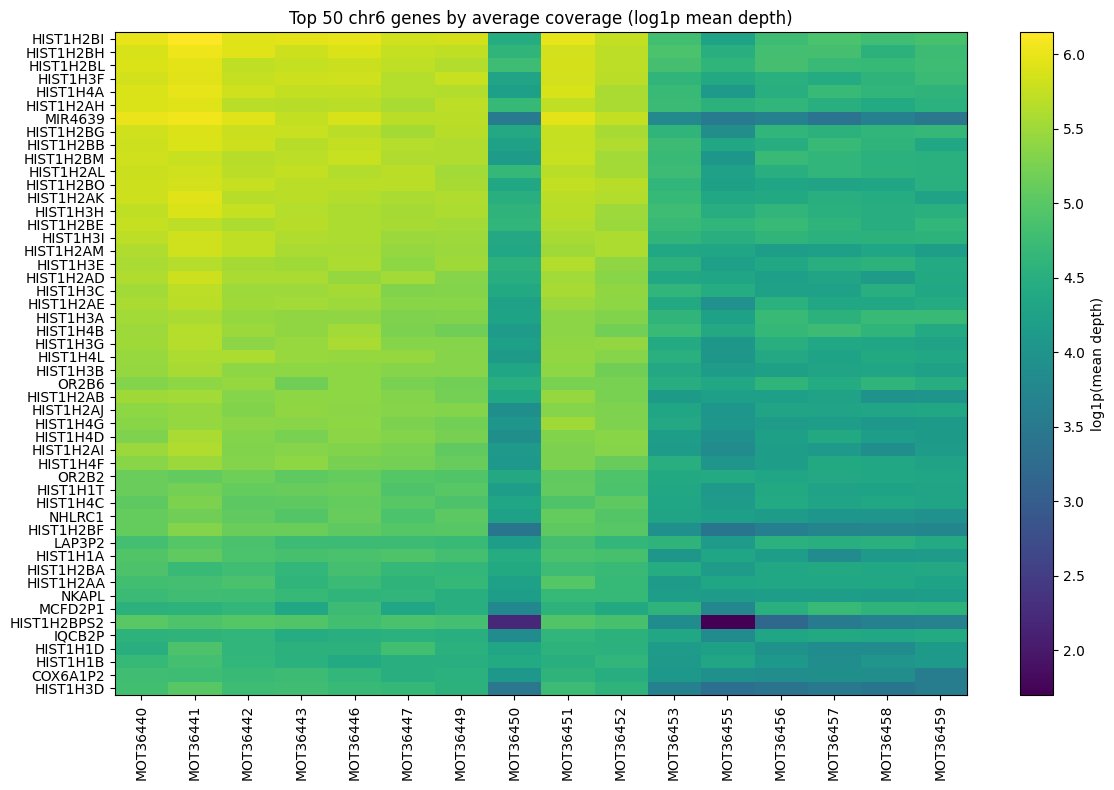

In [13]:
cov_mat = pd.read_csv(coverage_matrix_path, index_col=0).fillna(0.0)
print("Coverage matrix shape (genes x samples):", cov_mat.shape)

top_k = 10
top_sets = {}
for sample in cov_mat.columns:
    top_genes = cov_mat[sample].sort_values(ascending=False).head(top_k).index.tolist()
    top_sets[sample] = set(top_genes)

gene_freq = {}
for s, gset in top_sets.items():
    for g in gset:
        gene_freq[g] = gene_freq.get(g, 0) + 1

freq_df = pd.DataFrame(
    [{"gene_name": g, "top10_count": c, "top10_fraction": c / len(top_sets)} for g, c in gene_freq.items()]
).sort_values(["top10_count", "gene_name"], ascending=[False, True])

# Check selected MHC symbols against the Top-10 sets.
MHC_GENES_SET = {"HLA-A","HLA-B","HLA-C","HLA-DRB1","HLA-DQB1","MICA","MICB"}
mhc_in_top10 = []
for sample, gset in top_sets.items():
    hits = sorted(list(gset.intersection(MHC_GENES_SET)))
    mhc_in_top10.append({"sample": sample, "mhc_genes_in_top10": ", ".join(hits), "count": len(hits)})
mhc_top10_df = pd.DataFrame(mhc_in_top10).sort_values("count", ascending=False)

common_threshold = max(2, len(top_sets) // 2)
common_genes = freq_df[freq_df["top10_count"] >= common_threshold]["gene_name"].tolist()

N = 50
topN_genes = cov_mat.mean(axis=1).sort_values(ascending=False).head(N).index
plot_mat_log = np.log1p(cov_mat.loc[topN_genes])

plt.figure(figsize=(12, 8))
plt.imshow(plot_mat_log.values, aspect="auto", interpolation="nearest")
plt.colorbar(label="log1p(mean depth)")
plt.yticks(range(len(plot_mat_log.index)), plot_mat_log.index)
plt.xticks(range(len(plot_mat_log.columns)), plot_mat_log.columns, rotation=90)
plt.title(f"Top {N} chr6 genes by average coverage (log1p mean depth)")
plt.tight_layout()
plt.show()


**Saved observation.** Many labels in the top-50 heatmap are HIST1-family genes. Several sample columns have lower recorded depth than others. These observations describe the displayed calculation and do not establish differential expression or a mechanism for the coverage differences.

## 6. Mapping-quality and alignment summaries

The original QC cell combines SAMtools flag statistics, a MAPQ histogram, and an approximate signal from seven selected MHC genes. The numeric review thresholds are exploratory heuristics rather than validated acceptance criteria.

Read the saved outputs with these qualifications:

- Flagstat parsing retains only the first count in each `passed + failed` pair. Its fractions are not a complete accounting of both QC categories.
- The MAPQ histogram excludes unmapped, secondary, supplementary, and duplicate-marked records. Despite the saved plot title, it does not include every primary alignment. Only MAPQ 0–60 is counted; higher values, including 255 (unavailable), are omitted. QC-failed records are not explicitly excluded by this histogram function.
- Histogram panels use different y-axis scales. Compare their shapes cautiously rather than comparing bar heights directly across panels.
- The approximate MHC statistic averages over emitted pileup positions, omits positions without pileup columns, and stops at a maximum of 50,000 positions. It is not a full-span mean depth and does not enforce the same explicit MAPQ threshold as the gene-presence check.
- The QC CSV is written before issue labels are added. The displayed interpretation and saved CSV therefore contain different fields.

These statistics describe the supplied BAM subsets. The high mapped fraction should not be interpreted as the mapping rate of the original sequencing libraries.

[1/16] QC -> MOT36440
[2/16] QC -> MOT36441
[3/16] QC -> MOT36442
[4/16] QC -> MOT36443
[5/16] QC -> MOT36446
[6/16] QC -> MOT36447
[7/16] QC -> MOT36449
[8/16] QC -> MOT36450
[9/16] QC -> MOT36451
[10/16] QC -> MOT36452
[11/16] QC -> MOT36453
[12/16] QC -> MOT36455
[13/16] QC -> MOT36456
[14/16] QC -> MOT36457
[15/16] QC -> MOT36458
[16/16] QC -> MOT36459


,sample,total_reads,mapped_reads,paired_in_sequencing,properly_paired,mapped_fraction,proper_pair_fraction,mapq_values_counted,mean_mapq,median_mapq,mhc_mean_depth_est,mhc_positions_used
0,MOT36440,774474,774254,746528,741348,0.999716,0.993061,746308,52.140454,60.0,11.682016,11032
1,MOT36441,801747,801553,771772,765936,0.999758,0.992438,771578,52.059934,60.0,30.886928,16034
2,MOT36442,788741,788529,760088,754621,0.999731,0.992807,759876,52.360173,60.0,26.359241,20187
3,MOT36443,718715,718524,690499,684996,0.999734,0.992030,690308,52.432684,60.0,14.786744,14846
4,MOT36446,734935,734752,707500,701540,0.999751,0.991576,707317,52.521184,60.0,25.366658,20125
5,MOT36447,695497,695257,670690,666828,0.999655,0.994242,670450,52.619784,60.0,12.965005,11173
6,MOT36449,657836,657690,635368,631486,0.999778,0.993890,635222,52.294529,60.0,13.788231,14445
7,MOT36450,500133,500000,476002,473656,0.999734,0.995071,475869,52.948797,60.0,12.526700,11086
8,MOT36451,751654,751436,725490,720209,0.999710,0.992721,725272,52.470626,60.0,27.254121,20506
9,MOT36452,707606,707379,682122,677176,0.999679,0.992749,681895,52.474259,60.0,27.847008,27812


Saved QC summary table -> /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/qc_summary_table.csv


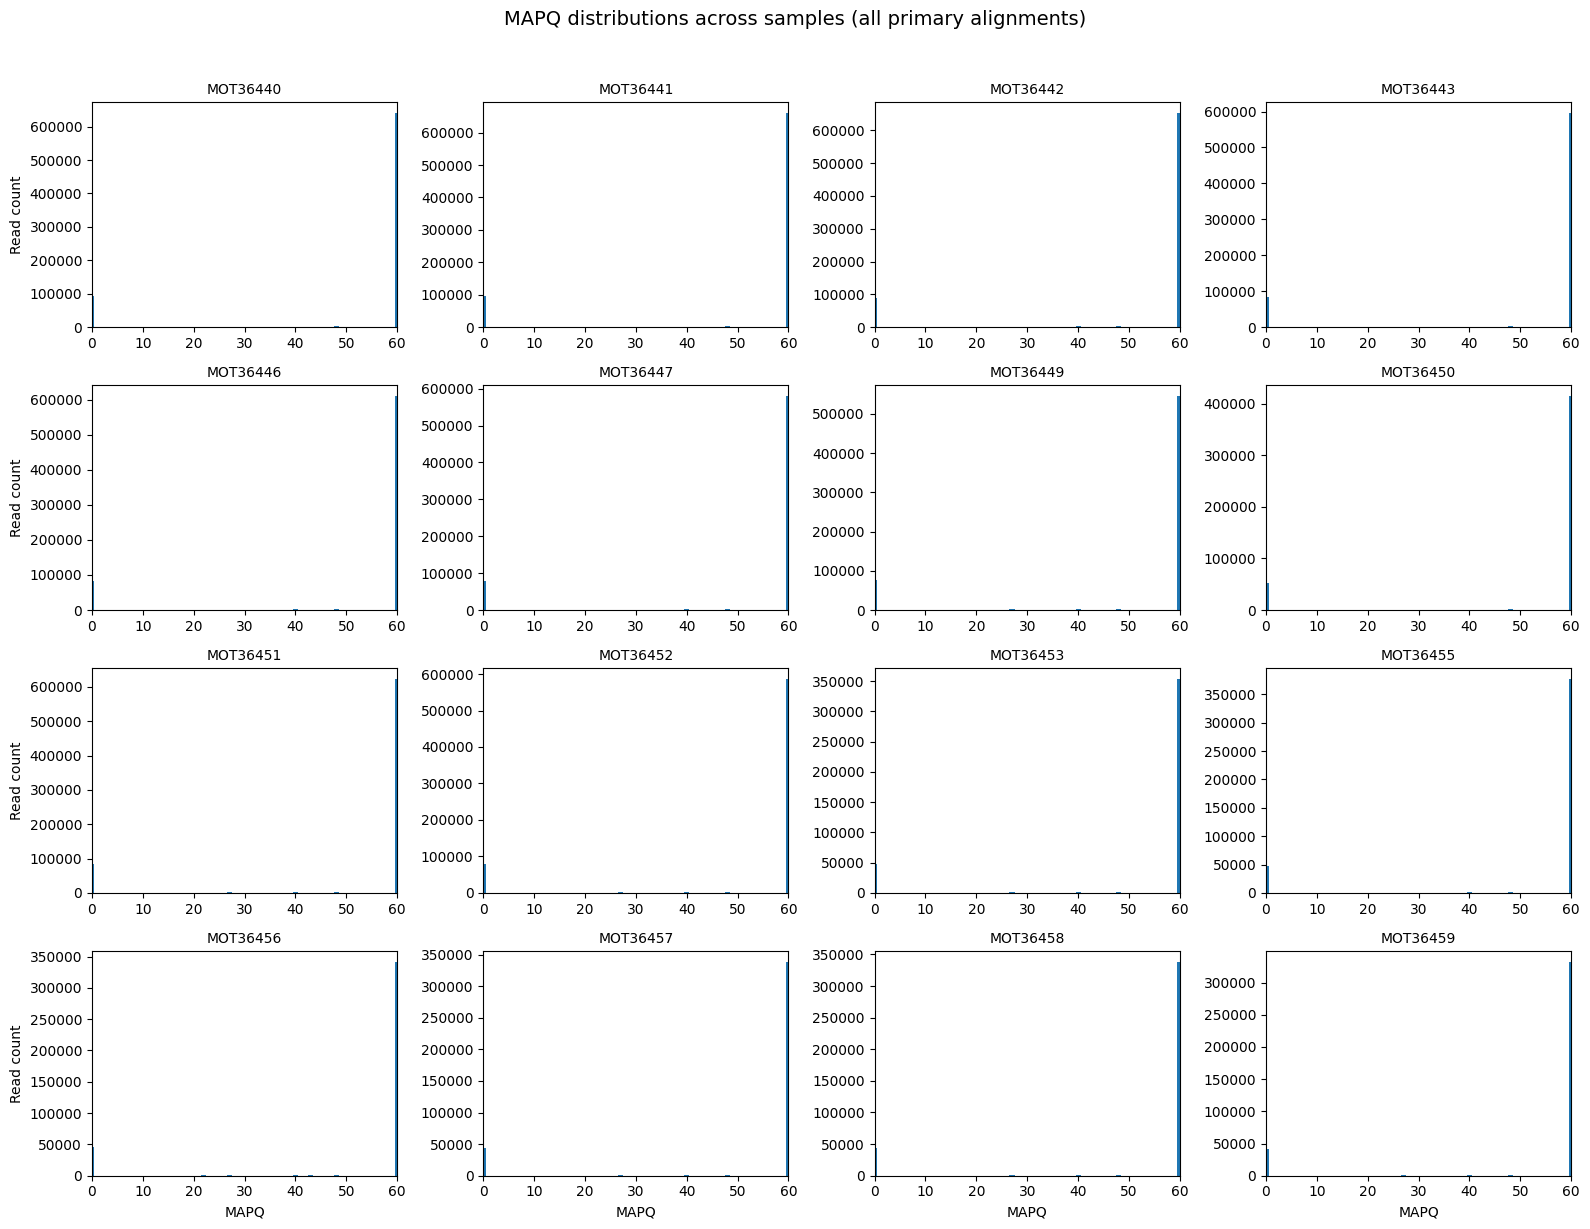


QC INTERPRETATION:
  No samples flagged by the heuristic thresholds.


In [9]:
THRESH_MAPPED_FRAC  = 0.80
THRESH_PROPER_FRAC  = 0.70
THRESH_MEDIAN_MAPQ  = 30

MHC_GENES = ["HLA-A","HLA-B","HLA-C","HLA-DRB1","HLA-DQB1","MICA","MICB"]
GENE_TABLE_PATH = genes_out

def run_flagstat(bam_path: str) -> str:
    res = subprocess.run(["samtools", "flagstat", bam_path], capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError(f"samtools flagstat failed for {bam_path}:\n{res.stderr}")
    return res.stdout

def parse_flagstat(text: str):
    total = mapped = properly_paired = paired_in_sequencing = 0
    m = re.search(r'(\d+)\s+\+\s+\d+\s+in total', text)
    if m: total = int(m.group(1))
    m = re.search(r'(\d+)\s+\+\s+\d+\s+mapped', text)
    if m: mapped = int(m.group(1))
    m = re.search(r'(\d+)\s+\+\s+\d+\s+paired in sequencing', text)
    if m: paired_in_sequencing = int(m.group(1))
    m = re.search(r'(\d+)\s+\+\s+\d+\s+properly paired', text)
    if m: properly_paired = int(m.group(1))
    return total, mapped, properly_paired, paired_in_sequencing

def mapq_hist_all_reads(bam_path: str):
    counts = np.zeros(61, dtype=np.int64)
    bam = pysam.AlignmentFile(bam_path, "rb")
    for read in bam.fetch():
        if read.is_unmapped or read.is_secondary or read.is_supplementary:
            continue
        if read.is_duplicate:
            continue
        q = read.mapping_quality
        if 0 <= q <= 60:
            counts[q] += 1
    bam.close()
    return counts, int(counts.sum())

def mean_median_from_hist(counts: np.ndarray):
    n = int(counts.sum())
    if n == 0:
        return np.nan, np.nan
    vals = np.arange(len(counts))
    mean = float((vals * counts).sum() / n)
    c = np.cumsum(counts)
    mid = (n - 1) / 2
    median = float(np.searchsorted(c, mid + 1))
    return mean, median

def mean_mhc_depth_approx(bam_path: str, gene_table_path: str, mhc_genes: list, max_positions: int = 50000):
    if not os.path.exists(gene_table_path):
        return np.nan, 0

    genes_df_local = pd.read_csv(gene_table_path)
    mhc_df = genes_df_local[genes_df_local["gene_name"].isin(mhc_genes)].copy()
    if mhc_df.empty:
        return np.nan, 0

    bam = pysam.AlignmentFile(bam_path, "rb")
    depth_sum = 0
    pos_count = 0

    for row in mhc_df.itertuples(index=False):
        chrom = getattr(row, "seqname")
        start = int(getattr(row, "start"))
        end = int(getattr(row, "end"))

        if chrom not in bam.references:
            if chrom == "6" and "chr6" in bam.references:
                chrom = "chr6"
            elif chrom == "chr6" and "6" in bam.references:
                chrom = "6"
            else:
                continue

        for col in bam.pileup(chrom, start - 1, end, truncate=True, stepper="samtools"):
            depth_sum += col.nsegments
            pos_count += 1
            if pos_count >= max_positions:
                bam.close()
                return (depth_sum / pos_count) if pos_count else np.nan, pos_count

    bam.close()
    return (depth_sum / pos_count) if pos_count else np.nan, pos_count

def flag_issues(row, mhc_median):
    issues = []
    if pd.notna(row["mapped_fraction"]) and row["mapped_fraction"] < THRESH_MAPPED_FRAC:
        issues.append(f"low_mapped_fraction<{THRESH_MAPPED_FRAC}")
    if pd.notna(row["proper_pair_fraction"]) and row["proper_pair_fraction"] < THRESH_PROPER_FRAC:
        issues.append(f"low_proper_pair_fraction<{THRESH_PROPER_FRAC}")
    if pd.notna(row["median_mapq"]) and row["median_mapq"] < THRESH_MEDIAN_MAPQ:
        issues.append(f"low_median_mapq<{THRESH_MEDIAN_MAPQ}")

    mhc_issue = ""
    if pd.notna(row["mhc_mean_depth_est"]) and pd.notna(mhc_median) and mhc_median > 0:
        if row["mhc_mean_depth_est"] < 0.25 * mhc_median:
            mhc_issue = "poor_mhc_signal"
    return issues, mhc_issue

qc_rows = []
mapq_hists = {}

for i, (sample, bam_path) in enumerate(BAM_PATHS.items(), start=1):
    if not os.path.exists(bam_path):
        print(f"[{i}/{len(BAM_PATHS)}] Skipping {sample}: BAM not found.")
        continue

    print(f"[{i}/{len(BAM_PATHS)}] QC -> {sample}")

    flagstat_text = run_flagstat(bam_path)
    total, mapped, properly_paired, paired_in_sequencing = parse_flagstat(flagstat_text)

    mapped_fraction = (mapped / total) if total else np.nan
    proper_pair_fraction = (properly_paired / paired_in_sequencing) if paired_in_sequencing else np.nan

    counts, n_counted = mapq_hist_all_reads(bam_path)
    mean_mapq, median_mapq = mean_median_from_hist(counts)
    mapq_hists[sample] = counts

    mhc_mean_depth, mhc_positions_used = mean_mhc_depth_approx(
        bam_path=bam_path,
        gene_table_path=GENE_TABLE_PATH,
        mhc_genes=MHC_GENES,
        max_positions=50000
    )

    qc_rows.append({
        "sample": sample,
        "total_reads": total,
        "mapped_reads": mapped,
        "paired_in_sequencing": paired_in_sequencing,
        "properly_paired": properly_paired,
        "mapped_fraction": mapped_fraction,
        "proper_pair_fraction": proper_pair_fraction,
        "mapq_values_counted": n_counted,
        "mean_mapq": mean_mapq,
        "median_mapq": median_mapq,
        "mhc_mean_depth_est": mhc_mean_depth,
        "mhc_positions_used": mhc_positions_used
    })

qc_df = pd.DataFrame(qc_rows).sort_values("sample").reset_index(drop=True)
display(qc_df)

qc_out_csv = os.path.join(OUTPUT_DIR, "qc_summary_table.csv")
qc_df.to_csv(qc_out_csv, index=False)
print("Saved QC summary table ->", qc_out_csv)

# Plot the retained MAPQ histograms.
samples = qc_df["sample"].tolist()
n = len(samples)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = np.array(axes).reshape(-1)

for ax_i, ax in enumerate(axes):
    if ax_i >= n:
        ax.axis("off")
        continue

    sample = samples[ax_i]
    counts = mapq_hists[sample]
    xs = np.arange(61)

    ax.bar(xs, counts, width=1.0)
    ax.set_title(sample, fontsize=10)
    ax.set_xlim(-1, 65)

    if ax_i % ncols == 0:
        ax.set_ylabel("Read count")
    if ax_i >= (nrows - 1) * ncols:
        ax.set_xlabel("MAPQ")

fig.suptitle("MAPQ distributions across samples (all primary alignments)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# Apply the original heuristic review thresholds.
mhc_median = float(qc_df["mhc_mean_depth_est"].median()) if qc_df["mhc_mean_depth_est"].notna().any() else np.nan

issues_list = []
mhc_issue_list = []
for _, row in qc_df.iterrows():
    issues, mhc_issue = flag_issues(row, mhc_median)
    issues_list.append(issues)
    mhc_issue_list.append(mhc_issue)

qc_df["issues"] = issues_list
qc_df["mhc_issue"] = mhc_issue_list

problematic = qc_df[(qc_df["issues"].astype(str) != "[]") | (qc_df["mhc_issue"] != "")]

print("\nQC INTERPRETATION:")
if problematic.empty:
    print("  No samples flagged by the heuristic thresholds.")
else:
    print("  Flagged samples:")
    for r in problematic.itertuples(index=False):
        issues_str = ", ".join(r.issues) if isinstance(r.issues, list) and r.issues else "none"
        mhc_str = r.mhc_issue if r.mhc_issue else "none"
        print(f"   - {r.sample}: issues=[{issues_str}] | mhc_issue={mhc_str}")


**Saved observation.** The original summary reports median MAPQ 60 for all 16 samples and no flags under its heuristic thresholds. This conclusion is restricted to the records and MAPQ range actually counted. High MAPQ does not establish complete coverage or unbiased alignment within the MHC.

## 7. Selected MHC genes: coverage and gaps

The panel includes three class I genes, two class II genes, six selected class III-region genes, and MICA/MICB. It is not a comprehensive MHC gene catalog.

The code reuses the per-sample annotation tables for FASTA export. Those FASTAs contain reference-genome sequences under sample-labeled headers; they are not sample consensus sequences and cannot support sample-specific allele inference.

**Different coverage definition:** this section uses `count_coverage` with a base-quality threshold of zero and the library's default read callback. It does not apply the earlier MAPQ ≥ 30 filter or explicitly exclude supplementary alignments. Its mean values should not be treated as directly equivalent to the earlier pileup metrics.

Gap fraction is the fraction of positions with zero counted depth across the entire annotated gene span, including introns. Without assay and target-region metadata, gaps cannot be assigned uniquely to capture failure, mapping difficulty, or biology.

**Repeated CFB record:** the mean-depth matrix uses duplicated symbol labels, while the gap plot aggregates matching symbols with a mean. The two figures therefore handle duplicated records differently. CFB-specific results should not be interpreted as two independent loci or as a validated single-gene summary.

The original hotspot statistic is retained in the code for provenance, but is not used for a biological conclusion: a median-plus-IQR threshold can be difficult to interpret in a zero-heavy depth distribution.

MHC targets:
  Class I : ['HLA-A', 'HLA-B', 'HLA-C']
  Class II: ['HLA-DRB1', 'HLA-DQB1']
  Class III (subset): ['C2', 'C4A', 'C4B', 'CFB', 'CYP21A2', 'TNF']
  MIC: ['MICA', 'MICB']
Found in chr6 table: ['HLA-A', 'HLA-C', 'HLA-B', 'MICA', 'MICB', 'TNF', 'C2', 'CFB', 'CFB', 'C4A', 'C4B', 'CYP21A2', 'HLA-DRB1', 'HLA-DQB1']

[1/16] Task 3A: MOT36440

[2/16] Task 3A: MOT36441

[3/16] Task 3A: MOT36442

[4/16] Task 3A: MOT36443

[5/16] Task 3A: MOT36446

[6/16] Task 3A: MOT36447

[7/16] Task 3A: MOT36449

[8/16] Task 3A: MOT36450

[9/16] Task 3A: MOT36451

[10/16] Task 3A: MOT36452

[11/16] Task 3A: MOT36453

[12/16] Task 3A: MOT36455

[13/16] Task 3A: MOT36456

[14/16] Task 3A: MOT36457

[15/16] Task 3A: MOT36458

[16/16] Task 3A: MOT36459

Saved MHC mean coverage matrix -> /content/drive/MyDrive/Bioinformatics/Assignments/Assignment1/output/mhc_mean_coverage_matrix.csv


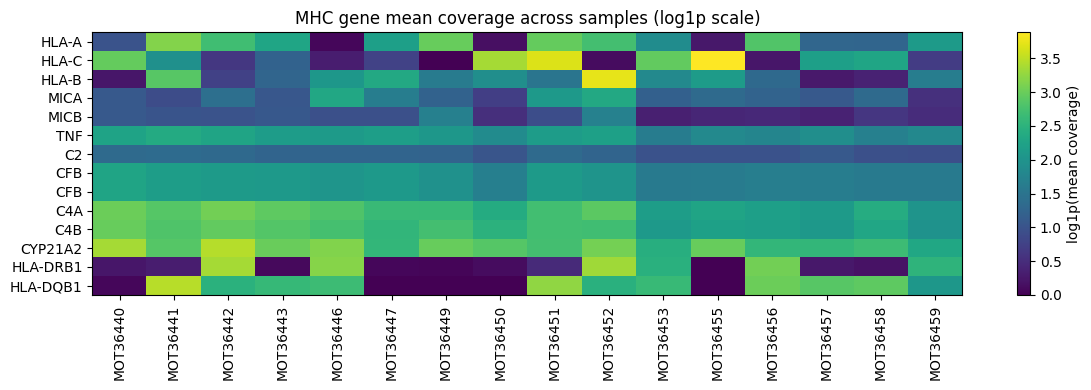

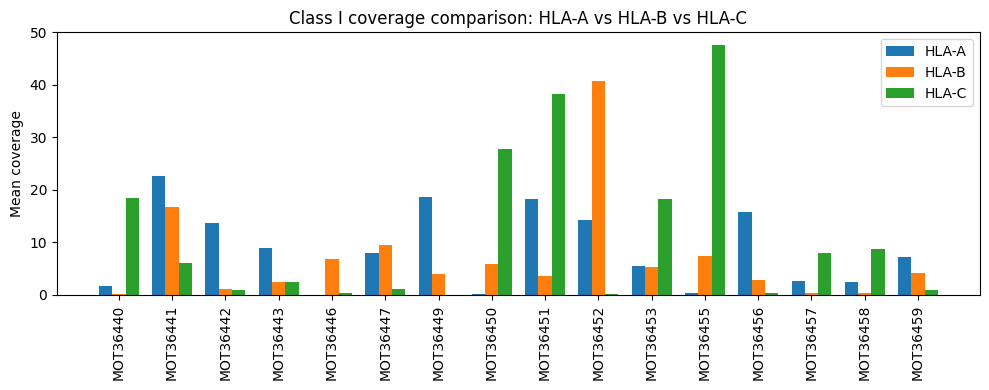

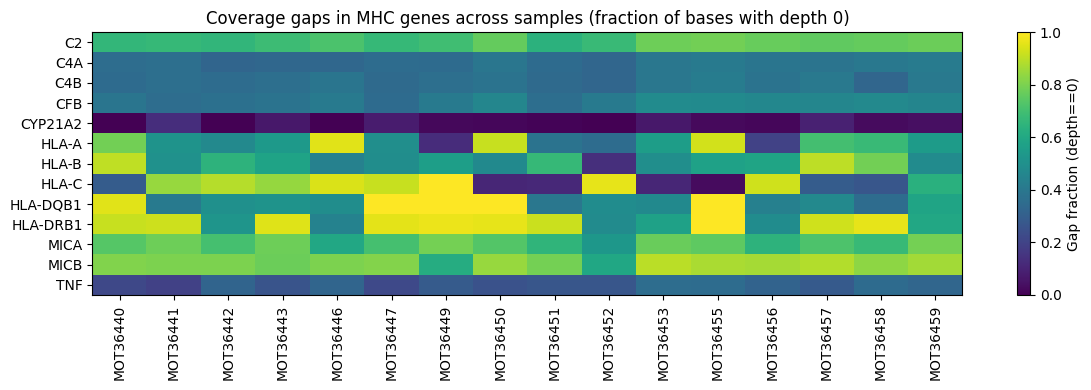

In [10]:
MHC_CLASS_I  = ["HLA-A", "HLA-B", "HLA-C"]
MHC_CLASS_II = ["HLA-DRB1", "HLA-DQB1"]
MHC_CLASS_III = ["C2", "C4A", "C4B", "CFB", "CYP21A2", "TNF"]  # subset
MIC_GENES = ["MICA", "MICB"]

ALL_MHC_GENES = MHC_CLASS_I + MHC_CLASS_II + MHC_CLASS_III + MIC_GENES

def mhc_class_of_gene(gene: str) -> str:
    if gene in MHC_CLASS_I:
        return "I"
    if gene in MHC_CLASS_II:
        return "II"
    if gene in MIC_GENES:
        return "MIC"
    if gene in MHC_CLASS_III:
        return "III"
    return "other"

genes_master_path = genes_out
genes_df = pd.read_csv(genes_master_path)

mhc_genes_df = genes_df[genes_df["gene_name"].isin(ALL_MHC_GENES)].copy()
mhc_genes_df["mhc_class"] = mhc_genes_df["gene_name"].apply(mhc_class_of_gene)

print("MHC targets:")
print("  Class I :", MHC_CLASS_I)
print("  Class II:", MHC_CLASS_II)
print("  Class III (subset):", MHC_CLASS_III)
print("  MIC:", MIC_GENES)
print("Found in chr6 table:", mhc_genes_df["gene_name"].tolist() if not mhc_genes_df.empty else "(none)")

mhc_fasta_dir = os.path.join(OUTPUT_DIR, "mhc_fastas")
mhc_cov_details_dir = os.path.join(OUTPUT_DIR, "mhc_coverage_details")
os.makedirs(mhc_fasta_dir, exist_ok=True)
os.makedirs(mhc_cov_details_dir, exist_ok=True)

def coverage_array_on_region(bam: pysam.AlignmentFile, chrom: str, start_1based: int, end_1based: int):
    cov_tuple = bam.count_coverage(chrom, start_1based - 1, end_1based, quality_threshold=0)
    counts = np.sum(np.array(cov_tuple, dtype=np.int64), axis=0)
    return counts

def gap_hotspot_summary(depths: np.ndarray):
    if depths.size == 0:
        return 0.0, 0.0, 0
    gap_fraction = float((depths == 0).mean())
    med = float(np.median(depths))
    q1 = float(np.quantile(depths, 0.25))
    q3 = float(np.quantile(depths, 0.75))
    iqr = max(q3 - q1, 1e-9)
    hotspot_threshold = med + 3 * iqr
    hotspot_fraction = float((depths >= hotspot_threshold).mean())
    max_depth = int(depths.max())
    return gap_fraction, hotspot_fraction, max_depth

coverage_matrix = pd.DataFrame(index=mhc_genes_df["gene_name"].values, columns=SAMPLES, dtype=float)
all_details_rows = []

for i, sample in enumerate(SAMPLES, start=1):
    bam_path = BAM_PATHS[sample]
    print(f"\n[{i}/{len(SAMPLES)}] Task 3A: {sample}")

    if not os.path.exists(bam_path):
        print("  BAM not found, skipping.")
        continue

    bam = pysam.AlignmentFile(bam_path, "rb")

    # Select MHC annotations for this sample.
    ann_file = os.path.join(OUTPUT_DIR, f"{sample}_gene_annotations.csv")
    mhc_table_out = os.path.join(OUTPUT_DIR, f"{sample}_mhc_gene_table.csv")

    mhc_ann_df = pd.DataFrame(columns=["gene_name","chromosome","start","end","strand","sequence"])
    if os.path.exists(ann_file):
        ann_df = pd.read_csv(ann_file)
        mhc_ann_df = ann_df[ann_df["gene_name"].isin(ALL_MHC_GENES)].copy()
        mhc_ann_df.to_csv(mhc_table_out, index=False)
    else:
        print("  WARNING: Missing Task 1 annotation:", ann_file)

    # Export reference sequences under the original sample-labeled headers.
    fasta_path = os.path.join(mhc_fasta_dir, f"{sample}_mhc_genes.fasta")
    with open(fasta_path, "w") as f:
        for row in mhc_ann_df.itertuples(index=False):
            gene = row.gene_name
            chrom = row.chromosome
            start = int(row.start)
            end = int(row.end)
            strand = row.strand
            seq = str(row.sequence)

            hdr = f">{sample}|{gene}|class={mhc_class_of_gene(gene)}|{chrom}:{start}-{end}|strand={strand}"
            f.write(hdr + "\n")
            for j in range(0, len(seq), 60):
                f.write(seq[j:j+60] + "\n")

    # Calculate the original MHC depth and gap statistics.
    details_rows = []
    for row in mhc_genes_df.itertuples(index=False):
        gene = row.gene_name
        chrom = row.seqname
        start = int(row.start)
        end = int(row.end)

        if chrom not in bam.references:
            if chrom == "6" and "chr6" in bam.references:
                chrom = "chr6"
            elif chrom == "chr6" and "6" in bam.references:
                chrom = "6"
            else:
                coverage_matrix.at[gene, sample] = np.nan
                continue

        depths = coverage_array_on_region(bam, chrom, start, end)
        mean_cov = float(depths.mean()) if depths.size else 0.0
        coverage_matrix.at[gene, sample] = mean_cov

        gap_frac, hotspot_frac, max_depth = gap_hotspot_summary(depths)

        details_rows.append({
            "sample": sample,
            "gene_name": gene,
            "mhc_class": mhc_class_of_gene(gene),
            "chromosome": chrom,
            "start": start,
            "end": end,
            "mean_coverage": mean_cov,
            "gap_fraction_depth0": gap_frac,
            "hotspot_fraction": hotspot_frac,
            "max_depth": max_depth,
            "region_length": int(end - start + 1)
        })

    bam.close()

    details_df = pd.DataFrame(details_rows).sort_values(["mhc_class","gene_name"])
    details_out = os.path.join(mhc_cov_details_dir, f"{sample}_mhc_coverage_details.csv")
    details_df.to_csv(details_out, index=False)
    all_details_rows.extend(details_rows)

# Save the original MHC matrix.
mhc_cov_matrix_path = os.path.join(OUTPUT_DIR, "mhc_mean_coverage_matrix.csv")
coverage_matrix.to_csv(mhc_cov_matrix_path)
print("\nSaved MHC mean coverage matrix ->", mhc_cov_matrix_path)

# Display mean depth, class I comparison, and zero-depth fractions.
plt.figure(figsize=(12, 4))
data = coverage_matrix.fillna(0).astype(float)
im = plt.imshow(np.log1p(data.values), aspect="auto", interpolation="nearest")
plt.colorbar(im, label="log1p(mean coverage)")
plt.yticks(range(len(data.index)), data.index)
plt.xticks(range(len(data.columns)), data.columns, rotation=90)
plt.title("MHC gene mean coverage across samples (log1p scale)")
plt.tight_layout()
plt.show()
print("\n")
classI = [g for g in MHC_CLASS_I if g in coverage_matrix.index]
if classI:
    plt.figure(figsize=(10, 4))
    x = np.arange(len(SAMPLES))
    width = 0.25
    for k, gene in enumerate(classI):
        vals = coverage_matrix.loc[gene, SAMPLES].fillna(0).values
        plt.bar(x + k*width, vals, width=width, label=gene)
    plt.xticks(x + width, SAMPLES, rotation=90)
    plt.ylabel("Mean coverage")
    plt.title("Class I coverage comparison: HLA-A vs HLA-B vs HLA-C")
    plt.legend()
    plt.tight_layout()
    plt.show()
print("\n")
all_details_df = pd.DataFrame(all_details_rows)
if not all_details_df.empty:
    gap_mat = all_details_df.pivot_table(
        index="gene_name",
        columns="sample",
        values="gap_fraction_depth0",
        aggfunc="mean"
    ).fillna(0)

    plt.figure(figsize=(12, 4))
    im = plt.imshow(gap_mat.values, aspect="auto", interpolation="nearest")
    plt.colorbar(im, label="Gap fraction (depth==0)")
    plt.yticks(range(len(gap_mat.index)), gap_mat.index)
    plt.xticks(range(len(gap_mat.columns)), gap_mat.columns, rotation=90)
    plt.title("Coverage gaps in MHC genes across samples (fraction of bases with depth 0)")
    plt.tight_layout()
    plt.show()


**Saved observation.** The retained figures show heterogeneous recorded coverage across genes and samples, together with substantial zero-depth fractions at several HLA loci. These are descriptive results from the original implementation. Their interpretation is limited by filtering differences, full-gene-span denominators, and duplicated gene symbols.

## 8. Why sample-specific HLA calls are not reported

The submitted notebook compared the reference sequences exported during annotation with a restricted set of IMGT/HLA allele sequences. Because the queries were extracted from `chr6.fa`, they did not contain sample-specific sequence variation. Repeated matches across samples could reflect reuse of the same reference query, not shared sample alleles.

The original implementation also parsed percent identity from formatted alignment text rather than aligned sequence coordinates, and assigned confidence categories from that value. Candidate references were restricted by sequence length and capped at 50 per gene. These calculations cannot establish sample genotypes or calibrated confidence.

The original allele-matching code and its frequency summary are omitted from this presentation. Their removal is a correction of interpretation, not a new HLA analysis. Sample-specific typing remains an unmet objective of the original assignment.

## 9. Conclusions and next steps

This archive demonstrates practical work with GTF and BAM files, reference-sequence extraction, alignment summaries, and comparative genomic visualization. Its retained results provide an exploratory view of the assigned samples, with the limitations of the implementation stated explicitly.

The raw inputs would be required to validate or revise the numerical results. A future rerun should use unique gene identifiers, verify reference compatibility, apply one documented coverage policy, distinguish uncomputed values from measured zeros, and assess coverage relative to the assay's intended targets. Sample-specific HLA analysis would require an appropriate read-based method and explicit handling of diploidy and ambiguity.

## Data and software provenance

- Course-provided BAM subset: 16 sample IDs listed in the configuration cell; original BAMs are currently unavailable.
- Annotation: GENCODE v19; the saved GTF header identifies GRCh37 and Ensembl 74.
- Reference sequence: local `chr6.fa`; exact source and checksum are not recorded in the supplied notebook.
- Original setup includes SAMtools, pysam, pandas, NumPy, Matplotlib, and Biopython. Installation commands are unpinned; the notebook does not establish a reproducible environment lockfile.
- The separate course report contains broader claims and figures. It has not been revised to match this edition and should not be treated as an independently verified account of this notebook.

## Editorial record

The retained executable code differs only in whitespace and comments; calculations, parameters, variable names, and plotting commands are preserved. The five embedded analytical figures and retained analysis outputs are unchanged. The installation log is omitted, section introductions and interpretations are rewritten, and the unsupported allele-matching section is removed. No analysis cells were executed during this cleanup.

Original cell numbers refer to the uploaded 20-cell notebook. Cells 1–18 are retained with the editorial changes described above; original cells 19–20 (allele matching and frequency reporting) are removed.